# M13.13 — Mondrian con 4a-G3T (enmienda 6)

Pre-registro: `docs/experiments/M13_13_G3T_taper.md`, sección "Enmienda 6", escrita antes de ejecutar.

- **Método:** exactamente el Mondrian de M13.7, con la selección y los hiperparámetros congelados de M11. Sus celdas 6 (ajuste) y 8 (test) se ejecutan desde el notebook cerrado, sin copiarlas. Cuantiles **solo con cal de G3T** y predicciones de 4a-G3T s123; evaluación en **test de G3T**. Política principal: conservative. Efficient se informa sin criterio.
- **Ruido de cal:** la cobertura condicionada a cal de un bin sigue Beta(k, n − k + 1), con k y n leídos del calibrador ajustado. Los aciertos en test siguen Beta-Binomial(m, k, n − k + 1).
- **Medidas:** (a) cobertura marginal con banda Monte Carlo del 95 % que incluye el ruido de cal, y el IC binomial ("solo test, sin ruido de cal"); (b) bins fuera de la banda Beta-Binomial del 99 % y P Poisson-binomial; (c) anchura por etiqueta y grupo de τ30, y frente a M13.7 (solo marginal, descriptivo); (d) los 9 eventos reales, reinferidos en CPU con gate frente al JSON de M13.13; (d′) distancia kNN de cada evento a cal frente a la distribución en test.
- **Criterio:** válida si, en las tres etiquetas, la cobertura marginal cae dentro de la banda Monte Carlo del 95 % y P(≥ n.º de bins fuera) ≥ 0,01. Si no, "cobertura no verificada". (d) y (d′) son descriptivos (n = 9).

> **Roles.** cal: solo los cuantiles Mondrian. val: referencia de RMSE y bordes de τ30. test: solo evaluación. Eventos reales: solo
> descripción. Nada se elige con test ni con eventos reales.

Solo CPU. Ejecutar por secciones. Entregado sin ejecutar.

## 1. Parámetros

In [1]:
TAG = "M13_13_4a_G3T_s123"
CHECKPOINT_REL = "M13_3/M13_13_4a_G3T_s123_final.pt"   # relative to <data_root>/models/checkpoints/
EXPECTED_CHECKPOINT_NAME = "M13_13_4a_G3T_s123_final.pt"
G3T_MARK = "m13_13_g3t"                  # G3T folder under the G3 dataset directory
HELDOUT_MEMMAP = "fp16_memmap_heldout"   # cal/test X of G3T

# Pre-registered checks (enmienda 6).
VAL_RMSE_REF = {"chirp_mass": 5.25, "total_mass": 8.76, "chi_eff": 0.168}    # val G3T, 4a-G3T (rounded)
VAL_RMSE_ROUNDING = {"chirp_mass": 0.005, "total_mass": 0.005, "chi_eff": 0.0005}
RMSE_REL_TOL = 0.05        # cal and test RMSE within +-5 % of val
Y_RTOL, Y_ATOL = 1e-5, 1e-6
TAU_EDGE_RTOL = 1e-6
GATE_TOLERANCE = 1e-4      # real-event predictions vs the M13.13 JSON, physical units

# Pre-registered measures and criterion (cal noise: Beta / Beta-Binomial).
MARGINAL_BAND_LEVEL = 0.95 # Monte Carlo band of the marginal coverage (criterion)
MC_SEED, MC_REPLICAS = 131301, 100_000
MARGINAL_CI_LEVEL = 0.95   # Clopper-Pearson, test only, no cal noise (reported, not the criterion)
BIN_BAND_LEVEL = 0.99      # central Beta-Binomial band per bin
P_MIN = 0.01
KNN_FAR_QUANTILE = 0.99    # "lejos de cal" above this test quantile; "fuera del rango de test" above the test max

REAL_EVENTS_STAMP = "20261110T130749Z"
EVAL_SUMMARY_NAME = "M13_13_G3T_evaluation_summary_20261110T124625Z.json"   # tau_edges_s of val G3T
M13_7_RUN = "run_20261102T164134Z"
OUT_OF_SUPPORT = {"GW200202_154313": "fuera de soporte (enmienda 5)"}
DEVICE = "cpu"

## 2. Imports y rutas

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from copy import copy
from dataclasses import replace
import sys, ast, json, pickle, hashlib, inspect, re, urllib.request, os
import h5py
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import beta, betabinom
from IPython.display import display

root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if root is None:
    raise RuntimeError("Abrir desde cbc_pe")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
# Same imports as M13.7 (cell 2), so that its reused cells find what they expect.
from src.paths import resolve_project_root, resolve_data_root, resolve_processed_artifact
from src.config import SimulationConfig
from src.processing import SignalProcessor
from src.models import network
from src.models.dataset import normalize_input_per_sample_per_detector_zscore
from src.real_data.catalog import get_event_detector_url
from src.real_data.gwosc_utils import read_gwosc_hdf5_as_pycbc_timeseries
from src.real_data.signal_processing import build_real_input_like_training, event_window_is_available_and_finite
from src.real_data.psd import select_valid_psd_window, estimate_offsource_psd
from src.real_data.inference import predict_real_with_embeddings
from src.real_data.event_runner import classify_failure_reason
from src.conformal.selected_calibrators import fit_selected_calibrators, apply_selected_calibrators
from src.conformal.pipeline import apply_mondrian, evaluate_mondrian, MondrianPrediction
from src.evaluation.lvk import add_lvk_comparison_metrics
import scripts.generate_m11_final_G1 as g1
from scripts.m13.generate_m13_G2_band import apply_overrides, config_sha256
from scripts.m13.generate_m13_G3_whitening import load_m13_config
from scripts.m13.m13_1_diagnostics import tau_newtonian   # tau30 of M13.1, as in the M13.13 evaluation

PROJECT_ROOT = resolve_project_root()
def read_json(path):
    return json.loads(Path(path).read_text())
def require(condition, message):
    if not condition:
        raise ValueError(message)
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

LABELS = ["chirp_mass", "total_mass", "chi_eff"]
DETECTORS = ["H1", "L1", "V1"]
POLICIES = ["conservative", "efficient"]
PRIMARY_POLICY = "conservative"
# Used only by the reused M13.7 cell 8, which prints its own operational criterion (not the criterion here).
COVERAGE_TOLERANCE = 0.02
MIN_BIN_N_FOR_CRITERION = 500

# G3 contract, as in M13.7 and M13_13_real_events: the 4b-G3 train config supplies dataset, split, scaler file
# and input normalization. G3T shares the G3 HDF5 labels, split and train-only scaler.
TRAIN_CFG_PATH = PROJECT_ROOT / "configs/experiments/m13/train_m13_4b_G3aug_s123.json"
GEN_M13_PATH = PROJECT_ROOT / "configs/generation/generate_m13_G3_band1024_w16.json"
train_cfg = read_json(TRAIN_CFG_PATH)
DATA_ROOT = resolve_data_root(config_data_root=train_cfg["data_root"])
DATASET_ID = train_cfg["dataset"]["dataset_id"]
require(DATASET_ID == "M13_G3_band1024_w16_500k", "Unexpected G3 dataset")
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
                                   file_name=train_cfg["dataset"]["dataset_file"])
SPLIT_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
                                        file_name=train_cfg["dataset"]["split_file"])
LABEL_STATS_PATH = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
                                              file_name=train_cfg["dataset"]["label_stats_file"])
HELDOUT_DIR = DATA_ROOT / "processed" / DATASET_ID / G3T_MARK / HELDOUT_MEMMAP
CHECKPOINT_ROOT = DATA_ROOT / "models/checkpoints"
CHECKPOINT = CHECKPOINT_ROOT / CHECKPOINT_REL

M13_DIR = DATA_ROOT / "results/M13_3"
NPZ_PATHS = {"cal": M13_DIR / "M13_13/preds_4a_G3T_on_G3T_cal/cal_predictions_embeddings.npz",
             "test": M13_DIR / "M13_13/preds_4a_G3T_on_G3T_test/test_predictions_embeddings.npz",
             "val": M13_DIR / TAG / "val_predictions_embeddings.npz"}
REAL_JSON = M13_DIR / "M13_13/real_events" / f"M13_13_real_events_{REAL_EVENTS_STAMP}.json"
EVAL_SUMMARY = M13_DIR / "M13_13" / EVAL_SUMMARY_NAME
REAL_EVENTS_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_13_real_events.ipynb"

M13_7_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_7_pipeline_provisional_4b.ipynb"
M13_7_DIR = M13_DIR / "M13_4b_G3aug_s123" / "M13_7_pipeline_provisional" / M13_7_RUN
M13_7_SUMMARY = M13_7_DIR / f"M13_7_summary_{M13_7_RUN.removeprefix('run_')}.json"

# M11 frozen Mondrian selection and hyperparameters (read by M13.7 cell 6).
M11_RESULTS = DATA_ROOT / "results/M11_final_G1_500k"
M11_SELECTION = M11_RESULTS / "mondrian_m11_selected_from_val.csv"
M11_BUNDLE_MANIFEST = M11_RESULTS / "mondrian_m11_selected_calibrators_frozen_provenance.json"

# Real-event cohort, cache and posterior samples exactly as M13.7 / M13_13_real_events.
M10_DATASET_ID = read_json(PROJECT_ROOT / "configs/experiments/train_500k_M10_inputzscore_resdilated_emb64_d124_bs256_seed123.json")["dataset"]["dataset_id"]
EVENT_LIST_PATH = DATA_ROOT / "results" / M10_DATASET_ID / "real_events_m10_500k_lvk_comparison/multi_event_all_catalog_candidates.csv"
GWOSC_CACHE = DATA_ROOT / "gwosc_cache"
PE_DIR = DATA_ROOT / "external/gwtc3_pe"
PE_VARIANT = "mixed_cosmo"
PE_GROUP = "C01:Mixed"
PE_LEVEL = 0.90
PE_Q = [(1 - PE_LEVEL) / 2, 1 - (1 - PE_LEVEL) / 2]

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUTPUT_DIR = M13_DIR / "M13_13/mondrian_G3T" / f"run_{RUN_STAMP}"

inputs_to_check = [("npz cal", NPZ_PATHS["cal"]), ("npz test", NPZ_PATHS["test"]), ("npz val", NPZ_PATHS["val"]),
    ("row_ids cal", HELDOUT_DIR / "row_ids_cal.npy"), ("row_ids test", HELDOUT_DIR / "row_ids_test.npy"),
    ("y cal (memmap)", HELDOUT_DIR / "y_cal.npy"), ("y test (memmap)", HELDOUT_DIR / "y_test.npy"),
    ("heldout manifest", HELDOUT_DIR / "manifest.json"),
    ("G3 HDF5", G3_H5), ("split", SPLIT_PATH), ("label stats (train only)", LABEL_STATS_PATH),
    ("checkpoint", CHECKPOINT), ("run_info", M13_DIR / TAG / "run_info.json"),
    ("M13.13 real events JSON", REAL_JSON), ("M13.13 evaluation summary", EVAL_SUMMARY),
    ("M13_13_real_events notebook", REAL_EVENTS_NOTEBOOK),
    ("M13.7 notebook", M13_7_NOTEBOOK), ("M13.7 summary", M13_7_SUMMARY),
    ("M11 selection (val)", M11_SELECTION), ("M11 bundle manifest", M11_BUNDLE_MANIFEST),
    ("G3 generation config", GEN_M13_PATH), ("cohort", EVENT_LIST_PATH)]
path_audit = pd.DataFrame([dict(role=r, path=str(p), exists=p.is_file()) for r, p in inputs_to_check])
with pd.option_context("display.max_colwidth", None):
    display(path_audit)
require(path_audit.exists.all(), "Missing required inputs; inspect path table")

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal


,role,path,exists
0,npz cal,/data/vserrano/cbc_pe_data/results/M13_3/M13_13/preds_4a_G3T_on_G3T_cal/cal_predictions_embeddings.npz,True
1,npz test,/data/vserrano/cbc_pe_data/results/M13_3/M13_13/preds_4a_G3T_on_G3T_test/test_predictions_embeddings.npz,True
2,npz val,/data/vserrano/cbc_pe_data/results/M13_3/M13_13_4a_G3T_s123/val_predictions_embeddings.npz,True
3,row_ids cal,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/row_ids_cal.npy,True
4,row_ids test,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/row_ids_test.npy,True
5,y cal (memmap),/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/y_cal.npy,True
6,y test (memmap),/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/y_test.npy,True
7,heldout manifest,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_13_g3t/fp16_memmap_heldout/manifest.json,True
8,G3 HDF5,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5,True
9,split,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/M11_final_G1_500k_splits_train400000_val40000_cal30000_test30000_seed123.npz,True


## 3. Código reutilizado, sin copiarlo

Mismo mecanismo que `M13_13_real_events.ipynb`: se ejecuta el código fuente de las celdas de los notebooks cerrados y se guarda su
sha256 en el JSON. Las celdas 16, 19 y 27 de M13.7 deben tener el mismo sha256 que las que usó la ejecución de eventos reales de M13.13.

| Origen | Celda | Qué se reutiliza |
|---|---|---|
| M13.7 | 11 | `read_hdf5_dataset_preserve_order` |
| M13.7 | 16 | Contrato G3: `processor`, contexto, PSD y comprobaciones frente al HDF5 |
| M13.7 | 19 | `prepare_nominal`, `check_psd_equivalence`, `infer` |
| M13.7 | 27 | `pe_file`, `read_pe_samples` |
| M13.7 | 6 | Ajuste Mondrian solo con cal (sección 5) |
| M13.7 | 8 | Aplicación y evaluación en test (sección 5) |
| M13_13_real_events | 10 | Celda completa: `load_kwargs` y `load_model` (checkpoint, `run_info` y escalador); `predict_events` no se usa |

In [3]:
m13_7_cells = read_json(M13_7_NOTEBOOK)["cells"]
real_events_cells = read_json(REAL_EVENTS_NOTEBOOK)["cells"]
reused_sources = {}

def reuse_cell(source, cells, cell_index, names=None):
    """Run a code cell of a closed notebook here, or only the functions in `names`."""
    cell = cells[cell_index]
    require(cell["cell_type"] == "code", f"{source} cell {cell_index} is not code")
    text = "".join(cell["source"])
    tree = ast.parse(text)
    if names is not None:
        tree.body = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in names]
        require({n.name for n in tree.body} == set(names), f"{source} cell {cell_index} does not define {names}")
    reused_sources[f"{source}/cell_{cell_index}"] = dict(names=names, sha256=hashlib.sha256(text.encode()).hexdigest())
    exec(compile(tree, f"{source}_cell_{cell_index}", "exec"), globals())

def reuse_m13_7(cell_index, names=None):
    reuse_cell("M13_7", m13_7_cells, cell_index, names)

reuse_m13_7(11, ["read_hdf5_dataset_preserve_order"])
reuse_m13_7(16)
reuse_m13_7(19, ["prepare_nominal", "check_psd_equivalence", "infer"])
reuse_m13_7(27, ["pe_file", "read_pe_samples"])
# Whole cell: load_model needs load_kwargs (torch.load arguments), defined at its top level.
reuse_cell("M13_13_real_events", real_events_cells, 10)

# Same M13.7 processing code as the M13.13 real-event run that produced REAL_JSON.
real_json = read_json(REAL_JSON)
for cell in ("cell_16", "cell_19", "cell_27"):
    require(reused_sources[f"M13_7/{cell}"]["sha256"] == real_json["provenance"]["reused_m13_7_cells"][cell]["sha256"],
            f"M13.7 {cell} differs from the one used by {REAL_JSON.name}")
print(json.dumps(reused_sources, indent=2))

{
  "context_samples": [
    33408,
    33408
  ],
  "processing_length": 83200,
  "psd_delta_f": 0.04923076923076923,
  "processing_flength": 41601,
  "psd_max_filter_duration_in_estimation": null,
  "whitening_max_filter_duration_in_processor": 16.0,
  "psd_segment_duration": 8.0,
  "nominal_psd_window": [
    -1024.0,
    -640.0
  ],
  "center_offset": 0.0,
  "zscore_eps": 1e-06,
  "g3_processing_configuration": {
    "lowpass_frequency_hz": 1024.0,
    "processing_context_end_samples": 33408,
    "processing_context_start_samples": 33408,
    "signal_processor": {
      "apply_highpass": true,
      "apply_lowpass": true,
      "apply_standardization": false,
      "fir_beta": 5.0,
      "fir_order": 256,
      "highpass_frequency": 30.0,
      "lowpass_frequency": 1024.0,
      "output_mode": "crop_to_config",
      "remove_corrupted": true,
      "whitening_low_frequency_cutoff": 30.0,
      "whitening_max_filter_duration": 16.0,
      "whitening_method": "psd",
      "whitening_

## 4. Comprobaciones previas (si falla alguna, el notebook se para)

Los npz guardan `pred_/y_/emb_/idx_` en espacio estandarizado con el escalador train-only. `y` se compara en unidades físicas
con el HDF5 de G3, lo que comprueba también las unidades. El RMSE se mide en unidades físicas. Si alguna comprobación falla, no se calibra.

In [4]:
CHECKS = []
def check(ok, name):
    require(bool(ok), "Check failed: " + name)
    CHECKS.append(name)

with np.load(LABEL_STATS_PATH) as stats:
    stats_mean, stats_std = (stats[k].astype(np.float32) for k in ("y_mean", "y_std"))

SPLITS, NPZ_PROVENANCE = {}, {}
for s, path in NPZ_PATHS.items():
    with np.load(path, allow_pickle=True) as z:
        check(z["available_splits"].tolist() == [s], f"{s}: npz holds only split {s}")
        check(z["label_names"].tolist() == LABELS, f"{s}: label order {LABELS}")
        prov = {k: str(z[k].item()) for k in ("checkpoint_file", "dataset_path", "split_path", "label_stats_path", "memmap_dir")}
        prov.update(model_class=z["model_config"].item()["class_name"], input_normalization=z["input_normalization"].item())
        check(np.array_equal(z["y_mean"], stats_mean) and np.array_equal(z["y_std"], stats_std),
              f"{s}: y_mean/y_std = train-only label stats")
        SPLITS[s] = dict(idx=np.asarray(z[f"idx_{s}"], dtype=np.int64), pred=np.asarray(z[f"pred_{s}"], dtype=float),
                         y=np.asarray(z[f"y_{s}"], dtype=float), emb=np.asarray(z[f"emb_{s}"], dtype=float))
    NPZ_PROVENANCE[s] = prov
    memmap_parts = Path(prov["memmap_dir"]).parts
    check(Path(prov["checkpoint_file"]).name == EXPECTED_CHECKPOINT_NAME, f"{s}: checkpoint_file is {EXPECTED_CHECKPOINT_NAME}")
    check(memmap_parts[-3:-1] == (DATASET_ID, G3T_MARK), f"{s}: memmap_dir is under {DATASET_ID}/{G3T_MARK}")
    if s in ("cal", "test"):
        check(memmap_parts[-1] == HELDOUT_MEMMAP, f"{s}: memmap_dir is {HELDOUT_MEMMAP}")
    check(Path(prov["split_path"]).name == SPLIT_PATH.name, f"{s}: split file")
    check(Path(prov["label_stats_path"]).name == LABEL_STATS_PATH.name, f"{s}: label stats file")
    check(prov["input_normalization"] == train_cfg["input_normalization"], f"{s}: input normalization contract")
check(len({p["model_class"] for p in NPZ_PROVENANCE.values()}) == 1, "same model class in the three npz")
y_mean, y_std = stats_mean.astype(float), stats_std.astype(float)
EMB_DIM_NPZ = SPLITS["cal"]["emb"].shape[1]

with np.load(SPLIT_PATH, allow_pickle=True) as z:
    split_indices = {s: np.asarray(z[f"{s}_idx"], dtype=np.int64) for s in ("train", "val", "cal", "test")}
heldout_manifest = read_json(HELDOUT_DIR / "manifest.json")
check(Path(heldout_manifest["source_hdf5"]["path"]).name == G3_H5.name, "heldout manifest: source HDF5 is the G3 HDF5")
ROW_IDS, IDX_SAME_ORDER_AS_ROW_IDS = {}, {}
for s, d in SPLITS.items():
    n = len(split_indices[s])
    check(d["idx"].shape == (n,) and len(np.unique(d["idx"])) == n, f"{s}: {n} unique idx")
    for name, width in (("pred", 3), ("y", 3), ("emb", EMB_DIM_NPZ)):
        check(d[name].shape == (n, width) and np.isfinite(d[name]).all(), f"{s}: {name} shape and finite")
    check(np.array_equal(np.sort(d["idx"]), np.sort(split_indices[s])), f"{s}: idx = split membership")
    if s in ("cal", "test"):
        row_ids = np.load(HELDOUT_DIR / f"row_ids_{s}.npy").astype(np.int64)
        check(heldout_manifest["splits"][s]["n_rows_written"] == n == len(row_ids), f"{s}: heldout rows written")
        check(np.array_equal(np.sort(d["idx"]), np.sort(row_ids)), f"{s}: idx = row_ids of {HELDOUT_MEMMAP}")
        ROW_IDS[s] = row_ids
        IDX_SAME_ORDER_AS_ROW_IDS[s] = bool(np.array_equal(d["idx"], row_ids))
for a, b in (("cal", "test"), ("cal", "val"), ("test", "val")):
    check(np.intersect1d(SPLITS[a]["idx"], SPLITS[b]["idx"]).size == 0, f"no overlap {a}/{b}")

# y of cal and test = y of the G3 HDF5 at those rows (and = y of the heldout memmap).
with h5py.File(G3_H5, "r") as h:
    check(h.attrs.get("experiment_id") == DATASET_ID, "G3 HDF5 experiment_id")
    check(str(h.attrs.get("labels")).split(",") == LABELS, "G3 HDF5 label order")
    y_h5 = {s: read_hdf5_dataset_preserve_order(h, "y", SPLITS[s]["idx"]).astype(float) for s in ("cal", "test")}
for s in ("cal", "test"):
    y_phys = SPLITS[s]["y"] * y_std + y_mean
    print(f"{s}: max |y_npz - y_h5| (physical) =", np.abs(y_phys - y_h5[s]).max(0))
    check(np.isclose(y_phys, y_h5[s], rtol=Y_RTOL, atol=Y_ATOL).all(), f"{s}: y = y of the G3 HDF5")
    y_mm = np.load(HELDOUT_DIR / f"y_{s}.npy").astype(float)
    order = np.argsort(ROW_IDS[s])
    pos = order[np.searchsorted(ROW_IDS[s][order], SPLITS[s]["idx"])]
    check(np.isclose(y_mm[pos], y_h5[s], rtol=Y_RTOL, atol=Y_ATOL).all(), f"{s}: heldout memmap y = y of the G3 HDF5")

# RMSE (physical): val reproduces the reference; cal and test within +-5 % of val.
rmse_rows = []
for s in ("val", "cal", "test"):
    err = (SPLITS[s]["pred"] - SPLITS[s]["y"]) * y_std
    rmse_rows.append(dict(split=s, n=len(err), **{l: float(np.sqrt(np.mean(err[:, j] ** 2))) for j, l in enumerate(LABELS)}))
rmse_table = pd.DataFrame(rmse_rows).set_index("split")
display(rmse_table)
for l in LABELS:
    check(abs(rmse_table.loc["val", l] - VAL_RMSE_REF[l]) <= VAL_RMSE_ROUNDING[l], f"val RMSE {l} = {VAL_RMSE_REF[l]}")
    for s in ("cal", "test"):
        rel = rmse_table.loc[s, l] / rmse_table.loc["val", l] - 1
        print(f"{s} {l}: RMSE {rmse_table.loc[s, l]:.4g} ({100 * rel:+.2f} % vs val)")
        check(abs(rel) <= RMSE_REL_TOL, f"{s} RMSE {l} within +-{100 * RMSE_REL_TOL:.0f} % of val")
print("Checks passed:", len(CHECKS))
print("idx in the same order as row_ids:", IDX_SAME_ORDER_AS_ROW_IDS)

cal: max |y_npz - y_h5| (physical) = [2.26102156e-06 7.93715662e-06 6.16398950e-08]
test: max |y_npz - y_h5| (physical) = [2.67509404e-06 7.89169644e-06 6.15315230e-08]


,n,chirp_mass,total_mass,chi_eff
split,,,,
val,40000,5.247980,8.759779,0.167675
cal,30000,5.295895,8.833631,0.169155
test,30000,5.297894,8.731181,0.164656


cal chirp_mass: RMSE 5.296 (+0.91 % vs val)
test chirp_mass: RMSE 5.298 (+0.95 % vs val)
cal total_mass: RMSE 8.834 (+0.84 % vs val)
test total_mass: RMSE 8.731 (-0.33 % vs val)
cal chi_eff: RMSE 0.1692 (+0.88 % vs val)
test chi_eff: RMSE 0.1647 (-1.80 % vs val)
Checks passed: 65
idx in the same order as row_ids: {'cal': True, 'test': True}


## 5. Mondrian de M13.7: ajuste solo con cal (celda 6) y evaluación en test (celda 8)

Se preparan las variables que esas celdas esperan y se ejecutan sin cambios. La celda 6 comprueba la selección y los hiperparámetros
congelados de M11, ajusta los seis sistemas solo con cal y serializa el bundle antes de tocar test. El bundle se escribe en el directorio
nuevo de esta ejecución.

**Aviso de procedencia:** el nombre del pickle (`mondrian_m13_7_4b_calibrators_cal_only.pkl`) y el campo `method_source` de sus
metadatos son texto fijo de la celda 6 de M13.7 y nombran a 4b-G3. Los campos `model`, `checkpoint_path` y `predictions_path` sí
corresponden a esta ejecución (4a-G3T, cal de G3T). Se deja constancia en el JSON.

La celda 8 imprime el criterio operativo de M13.7 (±2 puntos). Aquí se muestra solo como referencia. El criterio de la enmienda 6
está en la sección 6.

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Output:", OUTPUT_DIR)
pred_cal, y_cal, emb_cal = (SPLITS["cal"][k] for k in ("pred", "y", "emb"))
pred_test, y_test, emb_test, idx_test = (SPLITS["test"][k] for k in ("pred", "y", "emb", "idx"))
PREDICTIONS_PATH = NPZ_PATHS["cal"]   # field of M13.7 bundle metadata: the only predictions used for the fit
# M13.7 cell 6 records TAG/DATASET_ID in the bundle metadata: here, the G3T model and its data.
DATASET_ID_G3 = DATASET_ID
DATASET_ID = f"{DATASET_ID_G3}/{G3T_MARK}"
# M13.7 cell 6 binds `check` to a DataFrame (selection vs bundle merge); keep our check() helper.
check_helper = check
reuse_m13_7(6)
m13_7_selection_check, check = check, check_helper
DATASET_ID = DATASET_ID_G3
BUNDLE_NOTE = ("bundle file name and metadata.method_source are fixed text of M13.7 cell 6 (they name 4b-G3); "
               f"the bundle was fitted on G3T cal with {TAG} predictions ({NPZ_PATHS['cal']})")

# The method must be the one M13.7 used.
m13_7_summary = read_json(M13_7_SUMMARY)
check(m13_7_summary["mondrian"]["hyperparameters"] == HP, "Mondrian hyperparameters = M13.7")
ours_systems = selected[["final_policy", "label", "taxonomy_mode", "interval_mode", "n_bins"]].to_dict("records")
key = lambda r: (r["final_policy"], r["label"])
check(sorted(m13_7_summary["mondrian"]["systems"], key=key) ==
      sorted([{k: (int(v) if k == "n_bins" else v) for k, v in r.items()} for r in ours_systems], key=key),
      "Mondrian systems (taxonomy, interval mode, n_bins) = M13.7")

Output: /data/vserrano/cbc_pe_data/results/M13_3/M13_13/mondrian_G3T/run_20261110T234654Z


,final_policy,label,label_index,selection_policy,taxonomy_mode,interval_mode,n_bins
0,conservative,chirp_mass,0,conservative_zero_under_bins_2sigma,difficulty,asymmetric,16
1,efficient,chirp_mass,0,efficient_local_validity_tolerant,difficulty,asymmetric,48
2,conservative,total_mass,1,conservative_zero_under_bins_2sigma,prediction,asymmetric,4
3,efficient,total_mass,1,efficient_local_validity_tolerant,prediction,asymmetric,4
4,conservative,chi_eff,2,conservative_zero_under_bins_2sigma,difficulty,symmetric,8
5,efficient,chi_eff,2,efficient_local_validity_tolerant,difficulty,symmetric,4


fit cal only conservative/chirp_mass: difficulty/asymmetric/16
fit cal only efficient/chirp_mass: difficulty/asymmetric/48
fit cal only conservative/total_mass: prediction/asymmetric/4
fit cal only efficient/total_mass: prediction/asymmetric/4
fit cal only conservative/chi_eff: difficulty/symmetric/8
fit cal only efficient/chi_eff: difficulty/symmetric/4
Bundle: /data/vserrano/cbc_pe_data/results/M13_3/M13_13/mondrian_G3T/run_20261110T234654Z/mondrian_m13_7_4b_calibrators_cal_only.pkl d336cb32324db7a7f33888ba6a130dff6104a5c8634f4a7d9521b6800025b6b3


In [6]:
reuse_m13_7(8)

,final_policy,label,taxonomy_mode,interval_mode,n_bins,n_test,coverage,coverage_gap_points,marginal_pass,n_bins_assessed,n_bins_fail,min_bin_coverage_assessed,max_bin_coverage_assessed,min_bin_n,bins_pass,mean_width_phys,median_width_phys,lower_miss_rate,upper_miss_rate
0,conservative,chi_eff,difficulty,symmetric,8,30000,0.905067,0.506667,True,8,0,0.893878,0.912675,3660,True,0.541741,0.526796,0.050567,0.044367
1,conservative,chirp_mass,difficulty,asymmetric,16,30000,0.902767,0.276667,True,16,2,0.879467,0.924123,1785,False,14.908373,14.631974,0.050433,0.046800
2,conservative,total_mass,prediction,asymmetric,4,30000,0.907567,0.756667,True,4,0,0.900856,0.916170,7384,True,27.629117,23.663373,0.045133,0.047300
3,efficient,chi_eff,difficulty,symmetric,4,30000,0.906733,0.673333,True,4,0,0.902390,0.909115,7407,True,0.542699,0.510182,0.050100,0.043167
4,efficient,chirp_mass,difficulty,asymmetric,48,30000,0.901100,0.110000,True,48,12,0.854281,0.934505,549,False,14.916556,14.133480,0.051167,0.047733
5,efficient,total_mass,prediction,asymmetric,4,30000,0.907567,0.756667,True,4,0,0.900856,0.916170,7384,True,27.629117,23.663373,0.045133,0.047300


,final_policy,label,mondrian_bin,n,coverage,assessed,within_2_points,median_width_phys
0,conservative,chi_eff,0,3825,0.906144,True,True,0.436458
1,conservative,chi_eff,1,3733,0.900080,True,True,0.473508
2,conservative,chi_eff,2,3660,0.906284,True,True,0.492272
3,conservative,chi_eff,3,3794,0.906695,True,True,0.526796
4,conservative,chi_eff,4,3675,0.893878,True,True,0.538583
5,conservative,chi_eff,5,3732,0.909432,True,True,0.578207
6,conservative,chi_eff,6,3802,0.905050,True,True,0.609793
7,conservative,chi_eff,7,3779,0.912675,True,True,0.677216
8,conservative,chirp_mass,0,1816,0.908040,True,True,2.519469
9,conservative,chirp_mass,1,1884,0.903397,True,True,3.630910


CRITERION (fixed before test): |coverage - 0.90| <= 0.02; per bin only if n >= 500
  conservative chi_eff    marginal 0.9051 [PASS]  bins 8/8 within [PASS]
  conservative chirp_mass marginal 0.9028 [PASS]  bins 14/16 within [FAIL]
  conservative total_mass marginal 0.9076 [PASS]  bins 4/4 within [PASS]
  efficient    chi_eff    marginal 0.9067 [PASS]  bins 4/4 within [PASS]
  efficient    chirp_mass marginal 0.9011 [PASS]  bins 36/48 within [FAIL]
  efficient    total_mass marginal 0.9076 [PASS]  bins 4/4 within [PASS]


## 6. (a) Cobertura marginal y (b) por bin, con ruido de cal: criterio de la enmienda 6

**Ruido de cal.** La cobertura condicionada a cal de un bin con n_b filas de cal y rango k_b sigue Beta(k_b, n_b − k_b + 1). Los
aciertos en test con m_b filas siguen Beta-Binomial(m_b, k_b, n_b − k_b + 1). k_b y n_b se leen del calibrador que ajustó la celda 6
de M13.7 (`quantile_indices_`, índices desde 0, y `bin_counts_`) y se comprueban frente a los residuos de cal agrupados. En modo
simétrico, k = índice + 1 (cuantil de |r|). En modo asimétrico, la cobertura es U₍ₖ_high₎ − U₍ₖ_low₎ ~ Beta(k_high − k_low, ·), así que
k = k_high − k_low. El mínimo de 20 por bin solo se valida; no cambia el rango. Total_mass (taxonomía prediction) sigue la misma regla.

(a) Banda Monte Carlo del 95 % de la cobertura marginal: `default_rng(131301)`, 100 000 réplicas, un solo generador recorrido en el
orden ordenado (política, etiqueta). En cada réplica, c_b ~ Beta y aciertos ~ Binomial(m_b, c_b). También se da el IC de
Clopper–Pearson, "solo test, sin ruido de cal". (b) Banda central del 99 % de `betabinom(m_b, k_b, n_b − k_b + 1)` y P de dos colas
por bin. P(≥ n.º de bins fuera): Poisson-binomial exacta con la probabilidad de quedar fuera de cada bin. Solo cuentan los bins con
m_b > 0. El criterio se aplica a conservative; efficient se informa sin criterio.

In [7]:
def clopper_pearson(k, n, level):
    a = (1 - level) / 2
    lo = beta.ppf(a, k, n - k + 1) if k > 0 else 0.0
    hi = beta.ppf(1 - a, k + 1, n - k) if k < n else 1.0
    return float(lo), float(hi)

def cal_ranks(system):
    """(k_b, n_b) per bin from the fitted M13.7 calibrator: Beta(k_b, n_b - k_b + 1) is the cal-conditional coverage."""
    fitted, j = system.fitted, system.label_index
    cal = fitted.calibrator
    require(cal.interval_mode == system.interval_mode and cal.confidence_level == NOMINAL
            and cal.min_samples_per_bin == HP["min_samples_per_bin"], f"{system.label}: calibrator contract")
    n_b = np.asarray(cal.bin_counts_[j], dtype=int)
    idx = np.asarray(cal.quantile_indices_[j], dtype=int)            # (n_bins, 2), zero-based order statistics
    require(np.array_equal(n_b, np.bincount(fitted.bin_indices_cal[:, j], minlength=system.n_bins)),
            f"{system.label}: bin_counts_ differ from cal bin assignment")
    for b in range(system.n_bins):   # the indices really are the order statistics that give the offsets
        r = np.asarray(fitted.grouped_residuals_cal[j, b], dtype=float)
        require(r.size == n_b[b], f"{system.label} bin {b}: grouped residual count")
        if cal.interval_mode == "symmetric":
            require(idx[b, 0] == idx[b, 1] and np.sort(np.abs(r))[idx[b, 1]] == cal.intervals_[j, b, 1],
                    f"{system.label} bin {b}: symmetric rank not readable")
        else:
            s = np.sort(r)
            require(s[idx[b, 0]] == cal.intervals_[j, b, 0] and s[idx[b, 1]] == cal.intervals_[j, b, 1],
                    f"{system.label} bin {b}: asymmetric ranks not readable")
    k_b = idx[:, 1] + 1 if cal.interval_mode == "symmetric" else idx[:, 1] - idx[:, 0]
    require(((k_b >= 1) & (k_b <= n_b)).all(), f"{system.label}: rank outside [1, n]")
    return k_b, n_b, idx

def poisson_binomial_sf(p, k):
    """P(sum of independent Bernoulli(p_i) >= k), exact convolution."""
    pmf = np.array([1.0])
    for q in p:
        pmf = np.convolve(pmf, [1 - q, q])
    return float(pmf[k:].sum()) if k > 0 else 1.0

rng = np.random.default_rng(MC_SEED)   # one generator, fixed order: sorted (policy, label)
a_bin = (1 - BIN_BAND_LEVEL) / 2
marginal_rows, bin_band_rows, mc_coverage = [], [], {}
for (policy, label), r in sorted(test_results.items()):
    system, m = r["system"], r["metrics"]
    k_b, n_b, idx = cal_ranks(system)
    m_b = m["counts_per_bin"][:, 0].astype(int)
    hits_b = np.rint(m["coverage_per_bin"][:, 0] * m_b).astype(int)
    n_test = int(m_b.sum())
    require(n_test == len(r["width_phys"]), "test bin counts do not add up")
    cov = float(m["global_coverage"][0])
    require(int(hits_b.sum()) == int(np.rint(cov * n_test)), "per-bin hits do not add up to the marginal")

    # (a) Monte Carlo band with cal noise.
    c = rng.beta(k_b, n_b - k_b + 1, size=(MC_REPLICAS, len(k_b)))
    sim = rng.binomial(m_b, c).sum(axis=1) / n_test
    mc_lo, mc_hi = np.quantile(sim, [(1 - MARGINAL_BAND_LEVEL) / 2, 1 - (1 - MARGINAL_BAND_LEVEL) / 2])
    mc_coverage[(policy, label)] = sim
    ci_lo, ci_hi = clopper_pearson(int(hits_b.sum()), n_test, MARGINAL_CI_LEVEL)

    # (b) Beta-Binomial band per bin.
    p_out_list, n_out = [], 0
    for b in range(len(k_b)):
        row = dict(final_policy=policy, label=label, mondrian_bin=b, n_cal=int(n_b[b]), k_rank=int(k_b[b]),
                   quantile_index_low=int(idx[b, 0]), quantile_index_high=int(idx[b, 1]),
                   expected_coverage=float(k_b[b] / (n_b[b] + 1)), m_test=int(m_b[b]))
        if m_b[b] == 0:
            bin_band_rows.append(dict(row, hits=0, coverage=np.nan, band_lo=np.nan, band_hi=np.nan,
                                      p_out_exact=np.nan, p_two_sided=np.nan, outside_band=np.nan))
            continue
        dist = betabinom(m_b[b], k_b[b], n_b[b] - k_b[b] + 1)
        lo, hi = int(dist.ppf(a_bin)), int(dist.ppf(1 - a_bin))
        p_out = float(dist.cdf(lo - 1) + dist.sf(hi))
        p_two = float(min(1.0, 2 * min(dist.cdf(hits_b[b]), dist.sf(hits_b[b] - 1))))
        outside = bool(hits_b[b] < lo or hits_b[b] > hi)
        p_out_list.append(p_out)
        n_out += int(outside)
        bin_band_rows.append(dict(row, hits=int(hits_b[b]), coverage=float(hits_b[b] / m_b[b]), band_lo=lo / m_b[b],
                                  band_hi=hi / m_b[b], p_out_exact=p_out, p_two_sided=p_two, outside_band=outside))
    p_bins = poisson_binomial_sf(p_out_list, n_out)
    marginal_ok = bool(mc_lo <= cov <= mc_hi)
    marginal_rows.append(dict(final_policy=policy, label=label, taxonomy_mode=system.taxonomy_mode,
        interval_mode=system.interval_mode, n_bins=system.n_bins, n_test=n_test, coverage=cov,
        expected_coverage_H0=float(np.sum(m_b * k_b / (n_b + 1)) / n_test),
        mc95_lo=float(mc_lo), mc95_hi=float(mc_hi), coverage_in_mc_band=marginal_ok,
        binomial_ci95_lo_test_only=ci_lo, binomial_ci95_hi_test_only=ci_hi,
        n_bins_evaluated=len(p_out_list), n_bins_outside_99=n_out, expected_outside_H0=float(np.sum(p_out_list)),
        p_at_least_observed=p_bins, bins_ok=p_bins >= P_MIN,
        valid=bool(marginal_ok and p_bins >= P_MIN) if policy == PRIMARY_POLICY else None))
coverage_table = pd.DataFrame(marginal_rows)
bin_band_table = pd.DataFrame(bin_band_rows)
display(coverage_table)
with pd.option_context("display.max_rows", 400, "display.max_columns", 30):
    display(bin_band_table[bin_band_table.final_policy == PRIMARY_POLICY])

primary = coverage_table[coverage_table.final_policy == PRIMARY_POLICY]
require(len(primary) == 3, "Expected three primary systems")
VERDICT = "calibración válida en test" if primary.valid.all() else "cobertura no verificada"
print(f"CRITERIO (enmienda 6, {PRIMARY_POLICY}): cobertura marginal dentro de la banda MC {MARGINAL_BAND_LEVEL:.0%} "
      f"y P_PoissonBinomial(>= bins fuera de la banda Beta-Binomial {BIN_BAND_LEVEL:.0%}) >= {P_MIN}")
for r in primary.itertuples():
    print(f"  {r.label:10s} cov {r.coverage:.4f} MC [{r.mc95_lo:.4f}, {r.mc95_hi:.4f}] "
          f"{'OK' if r.coverage_in_mc_band else 'NO'} | bins fuera {r.n_bins_outside_99}/{r.n_bins_evaluated} "
          f"(esperados {r.expected_outside_H0:.2f}) P = {r.p_at_least_observed:.3g} {'OK' if r.bins_ok else 'NO'}"
          f" | binomial solo test [{r.binomial_ci95_lo_test_only:.4f}, {r.binomial_ci95_hi_test_only:.4f}]")
print("VEREDICTO:", VERDICT)

,final_policy,label,taxonomy_mode,interval_mode,n_bins,n_test,coverage,expected_coverage_H0,mc95_lo,mc95_hi,coverage_in_mc_band,binomial_ci95_lo_test_only,binomial_ci95_hi_test_only,n_bins_evaluated,n_bins_outside_99,expected_outside_H0,p_at_least_observed,bins_ok,valid
0,conservative,chi_eff,difficulty,symmetric,8,30000,0.905067,0.900027,0.895200,0.904800,False,0.901694,0.908361,8,0,0.076174,1.000000,True,False
1,conservative,chirp_mass,difficulty,asymmetric,16,30000,0.902767,0.900320,0.895500,0.905033,True,0.899358,0.906097,16,0,0.149361,1.000000,True,True
2,conservative,total_mass,prediction,asymmetric,4,30000,0.907567,0.899880,0.895033,0.904633,False,0.904233,0.910821,4,1,0.038561,0.038007,True,False
3,efficient,chi_eff,difficulty,symmetric,4,30000,0.906733,0.900013,0.895167,0.904800,False,0.903386,0.910001,4,0,0.038029,1.000000,True,None
4,efficient,chirp_mass,difficulty,asymmetric,48,30000,0.901100,0.899361,0.894533,0.904133,True,0.897666,0.904456,48,0,0.419050,1.000000,True,None
5,efficient,total_mass,prediction,asymmetric,4,30000,0.907567,0.899880,0.895067,0.904633,False,0.904233,0.910821,4,1,0.038561,0.038007,True,None


,final_policy,label,mondrian_bin,n_cal,k_rank,quantile_index_low,quantile_index_high,expected_coverage,m_test,hits,coverage,band_lo,band_hi,p_out_exact,p_two_sided,outside_band
0,conservative,chi_eff,0,3750,3376,3375,3375,0.900027,3825,3466,0.906144,0.881569,0.917124,0.009359,0.387083,False
1,conservative,chi_eff,1,3750,3376,3375,3375,0.900027,3733,3360,0.900080,0.881597,0.917225,0.009611,1.000000,False
2,conservative,chi_eff,2,3750,3376,3375,3375,0.900027,3660,3317,0.906284,0.881421,0.917486,0.009079,0.381606,False
3,conservative,chi_eff,3,3750,3376,3375,3375,0.900027,3794,3440,0.906695,0.881655,0.917238,0.009410,0.344633,False
4,conservative,chi_eff,4,3750,3376,3375,3375,0.900027,3675,3285,0.893878,0.881633,0.917279,0.009840,0.385513,False
5,conservative,chi_eff,5,3750,3376,3375,3375,0.900027,3732,3394,0.909432,0.881565,0.917203,0.009606,0.177006,False
6,conservative,chi_eff,6,3750,3376,3375,3375,0.900027,3802,3441,0.905050,0.881641,0.917149,0.009540,0.483276,False
7,conservative,chi_eff,7,3750,3376,3375,3375,0.900027,3779,3449,0.912675,0.881715,0.917174,0.009730,0.064544,False
8,conservative,chirp_mass,0,1875,1689,93,1782,0.900320,1816,1649,0.908040,0.873899,0.924559,0.009297,0.455865,False
9,conservative,chirp_mass,1,1875,1689,93,1782,0.900320,1884,1702,0.903397,0.874204,0.924098,0.009774,0.788938,False


CRITERIO (enmienda 6, conservative): cobertura marginal dentro de la banda MC 95% y P_PoissonBinomial(>= bins fuera de la banda Beta-Binomial 99%) >= 0.01
  chi_eff    cov 0.9051 MC [0.8952, 0.9048] NO | bins fuera 0/8 (esperados 0.08) P = 1 OK | binomial solo test [0.9017, 0.9084]
  chirp_mass cov 0.9028 MC [0.8955, 0.9050] OK | bins fuera 0/16 (esperados 0.15) P = 1 OK | binomial solo test [0.8994, 0.9061]
  total_mass cov 0.9076 MC [0.8950, 0.9046] NO | bins fuera 1/4 (esperados 0.04) P = 0.038 OK | binomial solo test [0.9042, 0.9108]
VEREDICTO: cobertura no verificada


## 7. (c) Anchura por etiqueta y por grupo de τ30

τ30 newtoniano con la Mc verdadera. Bordes de decil de val de G3T, como en la evaluación de M13.13 (comprobados frente a su
`tau_edges_s`), y aplicados a test. La comparación con M13.7 es marginal y descriptiva (otro predictor, otro dataset de entrenamiento,
otra calibración). M13.7 no guarda anchuras por τ30, así que esa parte se omite.

In [8]:
y_val_phys = SPLITS["val"]["y"] * y_std + y_mean
tau_edges = np.quantile(tau_newtonian(y_val_phys[:, 0]), np.linspace(0, 1, 11))
check(np.allclose(tau_edges, read_json(EVAL_SUMMARY)["tau_edges_s"], rtol=TAU_EDGE_RTOL, atol=0),
      "tau30 decile edges = M13.13 evaluation summary")
y_test_phys = y_test * y_std + y_mean
tau_test = tau_newtonian(y_test_phys[:, 0])
tdec_test = np.clip(np.searchsorted(tau_edges[1:-1], tau_test, side="right"), 0, 9)
TAU_GROUPS = {"D1-D3": tdec_test <= 2, "D4-D7": (tdec_test >= 3) & (tdec_test <= 6), "D8-D10": tdec_test >= 7}
GROUPS = {**TAU_GROUPS, "global": np.ones(len(tdec_test), bool)}
check(sum(int(g.sum()) for g in TAU_GROUPS.values()) == len(tdec_test), "tau groups partition test")

width_rows = []
for (policy, label), r in sorted(test_results.items()):
    w = r["width_phys"]
    for g, mask in GROUPS.items():
        width_rows.append(dict(final_policy=policy, label=label, group=g, n=int(mask.sum()),
                               mean_width_phys=float(w[mask].mean()), median_width_phys=float(np.median(w[mask]))))
width_table = pd.DataFrame(width_rows)
display(width_table.pivot_table(index=["final_policy", "label"], columns="group",
                                values=["mean_width_phys", "median_width_phys"]))

m13_7_widths = pd.DataFrame(m13_7_summary["test"]["summary"])[["final_policy", "label", "mean_width_phys", "median_width_phys"]]
width_vs_m13_7 = (width_table[width_table.group == "global"].drop(columns=["group", "n"])
                  .merge(m13_7_widths, on=["final_policy", "label"], suffixes=("_G3T", "_M13_7"), validate="one_to_one"))
width_vs_m13_7["mean_ratio_G3T_over_M13_7"] = width_vs_m13_7.mean_width_phys_G3T / width_vs_m13_7.mean_width_phys_M13_7
width_vs_m13_7["median_ratio_G3T_over_M13_7"] = width_vs_m13_7.median_width_phys_G3T / width_vs_m13_7.median_width_phys_M13_7
display(width_vs_m13_7)
print("Por τ30 frente a M13.7: omitido (el resumen de M13.7 solo guarda anchuras marginales).")

mean_width_phys                                   \
group                             D1-D3      D4-D7     D8-D10     global   
final_policy label                                                         
conservative chi_eff           0.556215   0.537620   0.532710   0.541741   
             chirp_mass       19.606462  16.741378   7.638671  14.908373   
             total_mass       34.752158  27.750398  20.243777  27.629117   
efficient    chi_eff           0.555828   0.539135   0.534267   0.542699   
             chirp_mass       19.655236  16.765137   7.584402  14.916556   
             total_mass       34.752158  27.750398  20.243777  27.629117   

                        median_width_phys                                   
group                               D1-D3      D4-D7     D8-D10     global  
final_policy label                                                          
conservative chi_eff             0.538583   0.526796   0.526796   0.526796  
             chirp_mass         18.968528  14.631974   5.387742  14.631974  
             total_mass         35.454771  23.663373  18.400410  23.663373  
efficient    chi_eff             0.555902   0.510182   0.510182   0.510182  
             chirp_mass         19.056043  15.376800   5.441831  14.133480  
             total_mass         35.454771  23.663373  18.400410  23.663373

,final_policy,label,mean_width_phys_G3T,median_width_phys_G3T,mean_width_phys_M13_7,median_width_phys_M13_7,mean_ratio_G3T_over_M13_7,median_ratio_G3T_over_M13_7
0,conservative,chi_eff,0.541741,0.526796,0.509585,0.490458,1.063102,1.074089
1,conservative,chirp_mass,14.908373,14.631974,13.273516,13.218064,1.123167,1.106968
2,conservative,total_mass,27.629117,23.663373,25.735062,22.824977,1.073598,1.036731
3,efficient,chi_eff,0.542699,0.510182,0.512877,0.475694,1.058145,1.072500
4,efficient,chirp_mass,14.916556,14.133480,13.204895,13.209014,1.129623,1.069988
5,efficient,total_mass,27.629117,23.663373,25.735062,22.824977,1.073598,1.036731


Por τ30 frente a M13.7: omitido (el resumen de M13.7 solo guarda anchuras marginales).


## 8. (d) Eventos reales y (d′) distancia kNN a cal

4a-G3T se reinfiere en CPU con el procesado de M13.7 (`prepare_nominal`, `check_psd_equivalence`) y el intervalo se calcula con
`infer` de M13.7 sobre el bundle de la sección 5. Gate: checkpoint con el mismo sha256 y predicciones iguales a las de
`M13_13_real_events_{REAL_EVENTS_STAMP}.json` con |Δ| ≤ 1e-4 en unidades físicas. Si falla, el notebook se para.

LVK: muestras `C01:Mixed`, mediana y 90 % central, que deben coincidir con las del JSON. `overlap` es la longitud de la intersección
del intervalo Mondrian con el 90 % de LVK; `overlap_fraction_lvk` es esa longitud dividida por la del 90 % de LVK.

(d′) Distancia media del embedding a sus 5 vecinos de cal, con el mismo `NearestNeighbors` del modelo de dificultad, situada en la
distribución de esa distancia en test. Marcas: "lejos de cal" por encima del P99 de test, "fuera del rango de test" por encima del
máximo. En total_mass el bin depende de la predicción y la distancia solo se informa.

In [9]:
EVENTS = real_json["events"]
require(len(EVENTS) == 9 and set(OUT_OF_SUPPORT) <= set(EVENTS), "Expected the 9 events of M13.13")
require(real_json["provenance"]["cohort_sha256"] == file_sha256(EVENT_LIST_PATH), "Cohort differs from M13.13 run")
dump_default = lambda o: o.item() if hasattr(o, "item") else str(o)   # as the M13.13 JSON writer
require(json.loads(json.dumps(processing_contract, default=dump_default)) == real_json["processing"],
        "G3 processing contract differs from the M13.13 real-event run")
real_model = next((m for m in real_json["models"] if m["tag"] == TAG), None)
require(real_model is not None, f"{TAG} not in {REAL_JSON.name}")

loaded = load_model(TAG, CHECKPOINT_REL)
require(loaded["provenance"]["checkpoint_sha256"] == real_model["checkpoint_sha256"], "Checkpoint differs from M13.13 run")
require(np.array_equal(loaded["y_mean"], y_mean) and np.array_equal(loaded["y_std"], y_std), "Checkpoint scaler differs from npz")
require(loaded["emb_dim"] == EMB_DIM_NPZ, "Embedding dimension differs from npz")
model, EMB_DIM = loaded["model"], loaded["emb_dim"]          # globals used by M13.7 `infer`
with BUNDLE_PATH.open("rb") as f:
    real_calibrators = pickle.load(f)["calibrators"]          # exactly the serialized cal-only bundle
require(set(real_calibrators) == {(p, l) for p in POLICIES for l in LABELS}, "Expected six systems")

cohort = pd.read_csv(EVENT_LIST_PATH)
require(not cohort.event.duplicated().any(), "Duplicate event in cohort")
cohort = cohort[cohort.event.isin(EVENTS)].reset_index(drop=True)
require(len(cohort) == 9, "Events missing from cohort")
interval_frames, point_frames, event_embeddings, processed_provenance = [], [], {}, []
for _, row in cohort.iterrows():
    print(row.event)
    X, diagnostics, meta, raw, psds, center, selected_window = prepare_nominal(
        row.event, row.gps_time, row.detectors, row["catalog"])
    check_psd_equivalence(raw, psds, center, selected_window)
    del raw, psds
    points, intervals = infer(row.event, X)
    pred_std_e, _, embedding = predict_real_with_embeddings(model, X, DEVICE, y_mean, y_std)
    require(np.allclose(pred_std_e[0] * y_std + y_mean, points.prediction.to_numpy(), rtol=0, atol=1e-6),
            f"{row.event}: embedding pass does not reproduce the prediction of infer")
    event_embeddings[row.event] = np.asarray(embedding, dtype=float)
    point_frames.append(points.assign(model=TAG))
    interval_frames.append(intervals.assign(model=TAG))
    processed_provenance.append(meta)
points = pd.concat(point_frames, ignore_index=True)
intervals = pd.concat(interval_frames, ignore_index=True)

# Gate against the M13.13 real-event JSON.
ref = pd.DataFrame(real_json["per_event"])
ref = ref[ref.model == TAG]
gate_table = points[["event", "label", "prediction"]].merge(
    ref[["event", "label", "prediction", "lvk_pe_median", "lvk_pe_lower90", "lvk_pe_upper90"]],
    on=["event", "label"], how="outer", suffixes=("", "_json"), validate="one_to_one")
require(len(gate_table) == 27 and gate_table.notna().all().all(), "GATE FAILED: events or labels differ from the JSON")
gate_table["delta"] = gate_table.prediction - gate_table.prediction_json
gate_max_abs_delta = float(gate_table.delta.abs().max())
print(f"max |delta| = {gate_max_abs_delta:.3e} (tolerance {GATE_TOLERANCE})")
require(gate_max_abs_delta <= GATE_TOLERANCE, "GATE FAILED: M13.13 predictions not reproduced; STOP")
print("GATE PASSED")

GW200202_154313


/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


GW200316_215756
GW191215_223052
GW200129_065458
GW200311_115853
GW200208_130117
GW200224_222234
GW200219_094415
GW191230_180458
max |delta| = 0.000e+00 (tolerance 0.0001)
GATE PASSED


In [10]:
# LVK posterior samples, read and checked as in M13_13_real_events (cell 16).
pe_paths = {event: pe_file(event) for event in EVENTS}
require(all(p is not None for p in pe_paths.values()), f"Missing PE files: {pe_paths}")
manifest_files = {f["key"]: f for m in sorted(PE_DIR.glob("manifest_*.json")) for f in read_json(m)["files"]}
pe_rows, pe_info = [], {}
for event, path in pe_paths.items():
    samples, info = read_pe_samples(path)
    entry = manifest_files.get(path.name)
    require(entry is not None and entry["size"] == info["size"], f"{path.name}: absent from download manifests or size differs")
    info["md5_zenodo"] = entry["md5"]
    pe_info[event] = info
    for j, label in enumerate(LABELS):
        lo, hi = np.quantile(samples[:, j], PE_Q)
        pe_rows.append(dict(event=event, label=label, lvk_pe_median=float(np.median(samples[:, j])),
                            lvk_pe_lower90=float(lo), lvk_pe_upper90=float(hi)))
pe_table = pd.DataFrame(pe_rows)
pe_check = pe_table.merge(gate_table, on=["event", "label"], suffixes=("", "_json"), validate="one_to_one")
for c in ("lvk_pe_median", "lvk_pe_lower90", "lvk_pe_upper90"):
    require(np.allclose(pe_check[c], pe_check[f"{c}_json"], rtol=1e-12, atol=0), f"LVK {c} differs from the M13.13 JSON")

# (d′) mean distance to the k nearest cal embeddings, with the NearestNeighbors of the difficulty model.
difficulty_systems = {key: s for key, s in real_calibrators.items() if s.taxonomy_mode == "difficulty"}
require(difficulty_systems, "No difficulty systems")
E = np.concatenate([event_embeddings[e] for e in EVENTS])
knn = {}
for key_, s in sorted(difficulty_systems.items()):
    dm = s.fitted.difficulty_model
    require(not dm.standardize_embeddings and dm.n_neighbors == HP["n_neighbors"], f"{key_}: unexpected difficulty model")
    knn[key_] = (dm.nn_model_.kneighbors(E, n_neighbors=dm.n_neighbors)[0].mean(1),
                 dm.nn_model_.kneighbors(emb_test, n_neighbors=dm.n_neighbors)[0].mean(1))
ref_key = sorted(knn)[0]
for key_, (d_e, d_t) in knn.items():   # every system is fitted on the same cal embeddings
    require(np.allclose(d_e, knn[ref_key][0], rtol=1e-12) and np.allclose(d_t, knn[ref_key][1], rtol=1e-12),
            f"{key_}: kNN distances differ between difficulty systems")
d_event, d_test = knn[ref_key]
d_test_q99, d_test_max = float(np.quantile(d_test, KNN_FAR_QUANTILE)), float(d_test.max())
knn_table = pd.DataFrame(dict(event=EVENTS, knn_mean_distance=d_event,
    test_percentile=[float(np.mean(d_test <= d)) for d in d_event]))
knn_table["knn_flag"] = np.where(d_event > d_test_max, "fuera del rango de test",
                                 np.where(d_event > d_test_q99, "lejos de cal", ""))
knn_test_summary = dict(n=int(len(d_test)), median=float(np.median(d_test)), q99=d_test_q99, max=d_test_max,
                        k=int(HP["n_neighbors"]), source_system=list(ref_key))
display(knn_table)
print(knn_test_summary)

# Per-event table.
real_table = intervals.merge(pe_table, on=["event", "label"], validate="many_to_one").merge(knn_table, on="event")
real_table["lvk_median_inside_mondrian"] = (real_table.lower <= real_table.lvk_pe_median) & (real_table.lvk_pe_median <= real_table.upper)
real_table["overlap"] = (np.minimum(real_table.upper, real_table.lvk_pe_upper90)
                         - np.maximum(real_table.lower, real_table.lvk_pe_lower90)).clip(lower=0)
real_table["overlap_fraction_lvk"] = real_table.overlap / (real_table.lvk_pe_upper90 - real_table.lvk_pe_lower90)
real_table["support"] = real_table.event.map(OUT_OF_SUPPORT).fillna("")
real_table["knn_bin_relevant"] = real_table.taxonomy_mode == "difficulty"
event_order = pe_table[pe_table.label == "chirp_mass"].sort_values("lvk_pe_median").event.tolist()
real_table["event_order"] = real_table.event.map({e: i for i, e in enumerate(event_order)})
real_table = real_table.sort_values(["policy", "label", "event_order"]).reset_index(drop=True)
with pd.option_context("display.max_rows", 100, "display.max_columns", 30):
    display(real_table[real_table.policy == PRIMARY_POLICY][["event", "label", "prediction", "lower", "upper", "width",
        "mondrian_bin", "taxonomy_mode", "lvk_pe_median", "lvk_pe_lower90", "lvk_pe_upper90", "lvk_median_inside_mondrian",
        "overlap", "overlap_fraction_lvk", "knn_mean_distance", "test_percentile", "knn_flag", "support"]])

,event,knn_mean_distance,test_percentile,knn_flag
0,GW200202_154313,0.342403,0.903233,
1,GW200316_215756,0.222698,0.589967,
2,GW191215_223052,0.273381,0.766800,
3,GW200129_065458,0.195912,0.463500,
4,GW200311_115853,0.130008,0.084500,
5,GW200208_130117,0.228217,0.612200,
6,GW200224_222234,0.132792,0.098333,
7,GW200219_094415,0.124954,0.063467,
8,GW191230_180458,0.144531,0.162600,


{'n': 30000, 'median': 0.20299268882028104, 'q99': 0.5075922030974696, 'max': 2.4799600878394195, 'k': 5, 'source_system': ['conservative', 'chi_eff']}


,event,label,prediction,lower,upper,width,mondrian_bin,taxonomy_mode,lvk_pe_median,lvk_pe_lower90,lvk_pe_upper90,lvk_median_inside_mondrian,overlap,overlap_fraction_lvk,knn_mean_distance,test_percentile,knn_flag,support
0,GW200202_154313,chi_eff,0.614383,0.377629,0.851137,0.473508,1,difficulty,0.039397,-0.017925,0.165387,False,0.000000,0.000000,0.342403,0.903233,,fuera de soporte (enmienda 5)
1,GW200316_215756,chi_eff,0.059770,-0.245126,0.364666,0.609793,6,difficulty,0.126015,0.024449,0.394471,True,0.340217,0.919453,0.222698,0.589967,,
2,GW191215_223052,chi_eff,-0.318642,-0.587934,-0.049350,0.538583,4,difficulty,-0.041186,-0.249205,0.127465,False,0.199855,0.530583,0.273381,0.766800,,
3,GW200129_065458,chi_eff,0.059733,-0.203664,0.323131,0.526796,3,difficulty,0.112242,-0.045292,0.226079,True,0.271371,1.000000,0.195912,0.463500,,
4,GW200311_115853,chi_eff,-0.023374,-0.286772,0.240023,0.526796,3,difficulty,-0.019349,-0.221190,0.135785,True,0.356975,1.000000,0.130008,0.084500,,
5,GW200208_130117,chi_eff,-0.201882,-0.438637,0.034872,0.473508,1,difficulty,-0.068255,-0.335154,0.148360,True,0.370026,0.765284,0.228217,0.612200,,
6,GW200224_222234,chi_eff,0.070066,-0.166688,0.306820,0.473508,1,difficulty,0.099130,-0.052838,0.245857,True,0.298696,1.000000,0.132792,0.098333,,
7,GW200219_094415,chi_eff,-0.374415,-0.713023,-0.035807,0.677216,7,difficulty,-0.080007,-0.369986,0.151118,True,0.334180,0.641291,0.124954,0.063467,,
8,GW191230_180458,chi_eff,-0.222626,-0.511730,0.066477,0.578207,5,difficulty,-0.049291,-0.356926,0.213097,True,0.423403,0.742783,0.144531,0.162600,,
9,GW200202_154313,chirp_mass,10.755368,9.463023,11.982492,2.519469,0,difficulty,8.148216,8.100908,8.197289,False,0.000000,0.000000,0.342403,0.903233,,fuera de soporte (enmienda 5)


## 9. Figuras

(1) Cobertura por bin en test con la banda binomial del 99 % (conservative). (2) Anchura por grupo de τ30, con la anchura media marginal
de M13.7 como referencia descriptiva. (3) Los 9 eventos: intervalo Mondrian, 90 % de LVK y predicción.

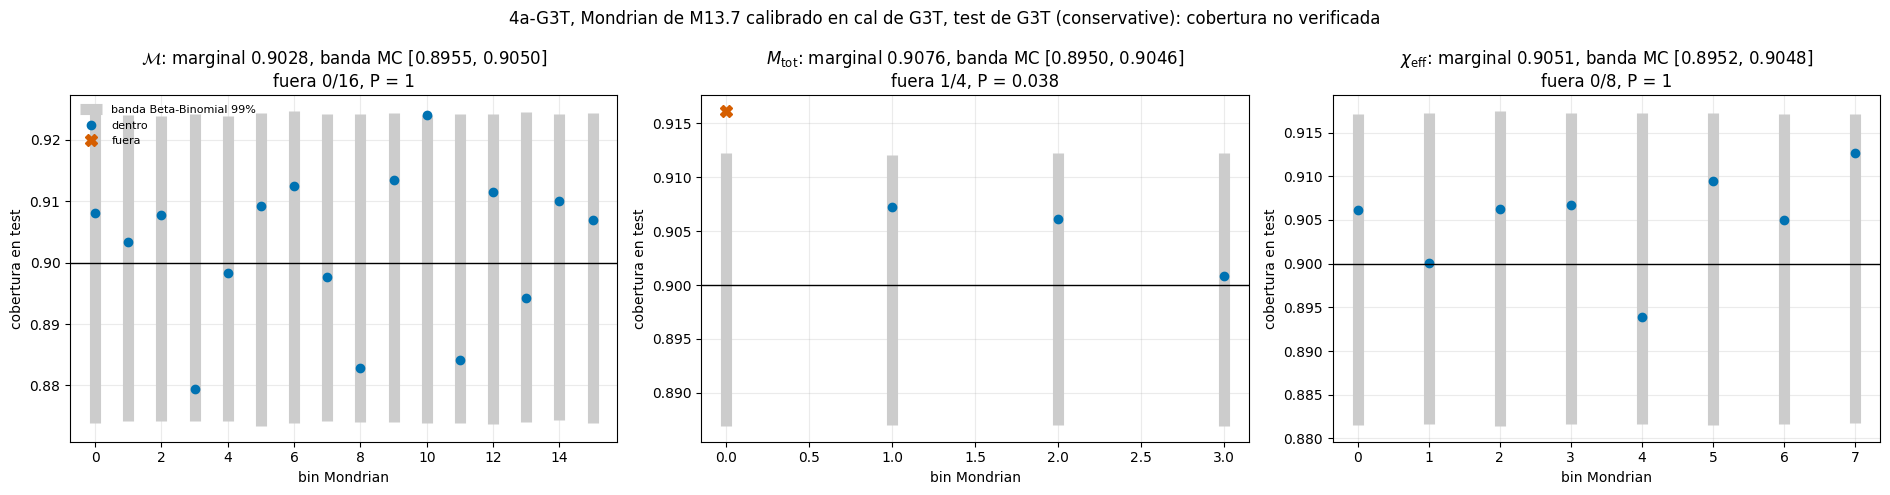

/tmp/ipykernel_85320/3627252233.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([w[GROUPS[g]] for g in group_names], labels=group_names, showfliers=False, whis=(5, 95))
/tmp/ipykernel_85320/3627252233.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([w[GROUPS[g]] for g in group_names], labels=group_names, showfliers=False, whis=(5, 95))
/tmp/ipykernel_85320/3627252233.py:36: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([w[GROUPS[g]] for g in group_names], labels=group_names, showfliers=False, whis=(5, 95))


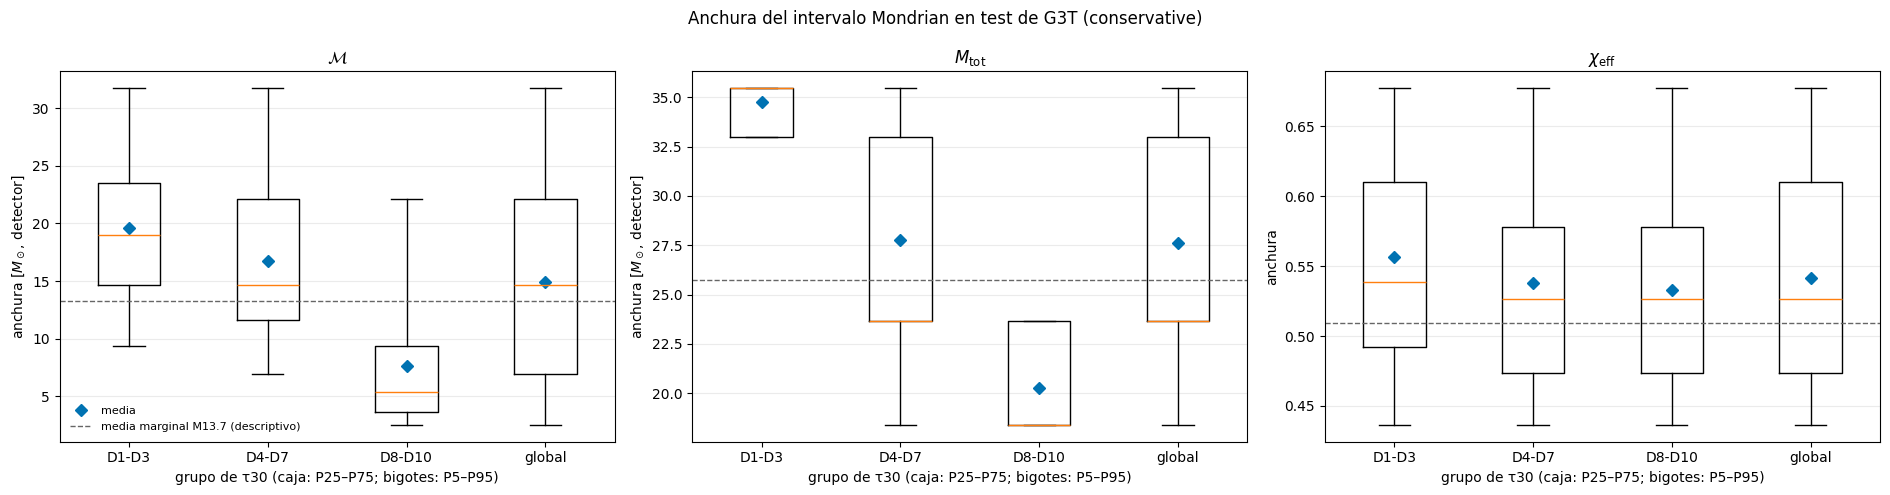

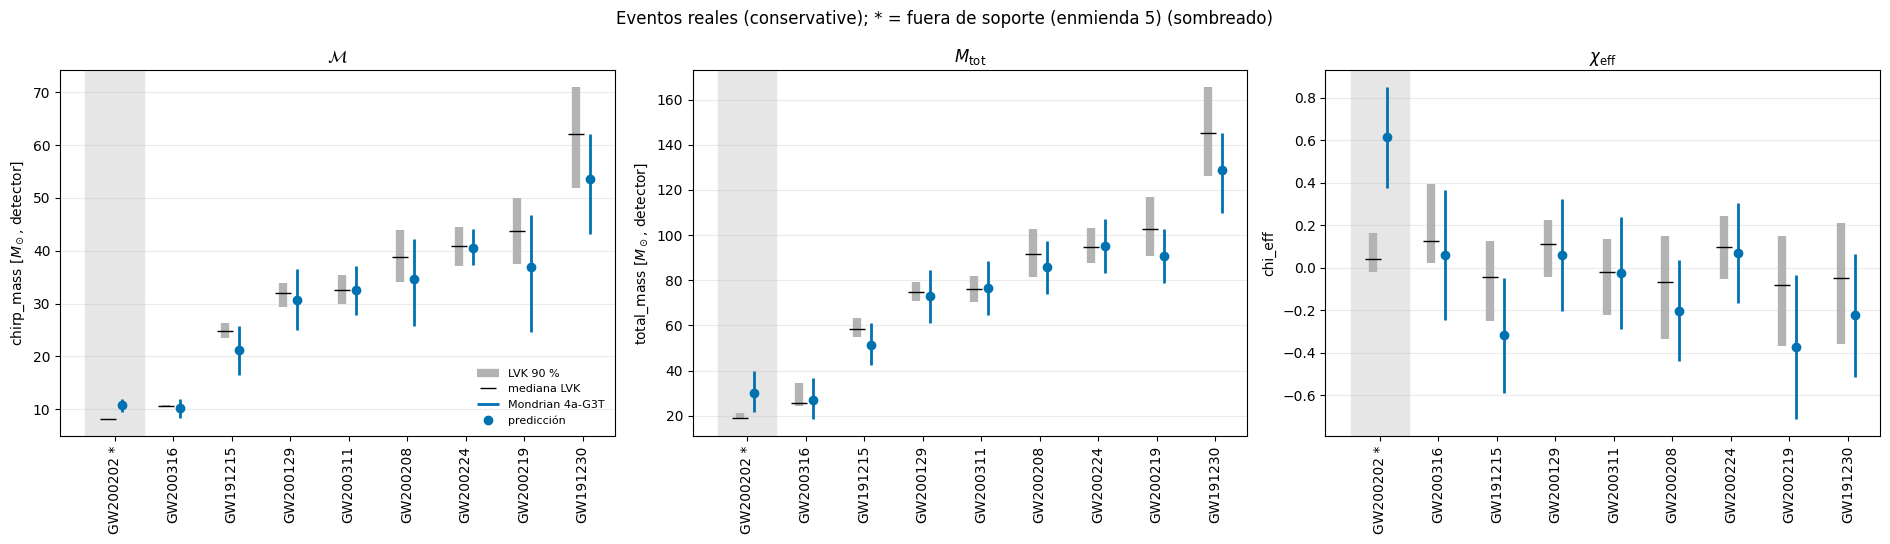

In [11]:
NICE_LABELS = {"chirp_mass": r"$\mathcal{M}$", "total_mass": r"$M_{\mathrm{tot}}$", "chi_eff": r"$\chi_\mathrm{eff}$"}
UNIT = {"chirp_mass": r" [$M_\odot$, detector]", "total_mass": r" [$M_\odot$, detector]", "chi_eff": ""}
figure_paths = []
def save_figure(fig, name):
    path = OUTPUT_DIR / f"M13_13_mondrian_G3T_{RUN_STAMP}_{name}.png"
    with path.open("xb") as f:
        fig.savefig(f, format="png", dpi=150, bbox_inches="tight")
    figure_paths.append(str(path))
    plt.show()
    plt.close(fig)

# (1) Coverage per bin with the binomial band.
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, label in zip(axes, LABELS):
    t = bin_band_table[(bin_band_table.final_policy == PRIMARY_POLICY) & (bin_band_table.label == label) & (bin_band_table.m_test > 0)]
    row = primary.set_index("label").loc[label]
    ax.vlines(t.mondrian_bin, t.band_lo, t.band_hi, color="0.8", linewidth=8, label=f"banda Beta-Binomial {BIN_BAND_LEVEL:.0%}")
    out = t.outside_band.astype(bool)
    ax.plot(t.mondrian_bin[~out], t.coverage[~out], "o", color="#0072B2", label="dentro")
    ax.plot(t.mondrian_bin[out], t.coverage[out], "X", color="#D55E00", markersize=9, label="fuera")
    ax.axhline(NOMINAL, color="black", linewidth=1)
    ax.set(title=f"{NICE_LABELS[label]}: marginal {row.coverage:.4f}, banda MC [{row.mc95_lo:.4f}, {row.mc95_hi:.4f}]\n"
                 f"fuera {row.n_bins_outside_99}/{row.n_bins_evaluated}, P = {row.p_at_least_observed:.3g}",
           xlabel="bin Mondrian", ylabel="cobertura en test")
    ax.grid(alpha=.25)
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle(f"4a-G3T, Mondrian de M13.7 calibrado en cal de G3T, test de G3T ({PRIMARY_POLICY}): {VERDICT}")
fig.tight_layout()
save_figure(fig, "coverage_per_bin")

# (2) Width per tau30 group.
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
group_names = list(GROUPS)
for ax, label in zip(axes, LABELS):
    w = test_results[(PRIMARY_POLICY, label)]["width_phys"]
    ax.boxplot([w[GROUPS[g]] for g in group_names], labels=group_names, showfliers=False, whis=(5, 95))
    ax.plot(np.arange(1, len(group_names) + 1), [w[GROUPS[g]].mean() for g in group_names], "D", color="#0072B2", label="media")
    m7 = width_vs_m13_7.set_index(["final_policy", "label"]).loc[(PRIMARY_POLICY, label), "mean_width_phys_M13_7"]
    ax.axhline(m7, color="0.4", linestyle="--", linewidth=1, label="media marginal M13.7 (descriptivo)")
    ax.set(title=NICE_LABELS[label], xlabel="grupo de τ30 (caja: P25–P75; bigotes: P5–P95)", ylabel="anchura" + UNIT[label])
    ax.grid(axis="y", alpha=.25)
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle(f"Anchura del intervalo Mondrian en test de G3T ({PRIMARY_POLICY})")
fig.tight_layout()
save_figure(fig, "width_by_tau30")

# (3) Real events.
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, label in zip(axes, LABELS):
    t = real_table[(real_table.policy == PRIMARY_POLICY) & (real_table.label == label)].sort_values("event_order")
    x = np.arange(len(t))
    ax.vlines(x - .12, t.lvk_pe_lower90, t.lvk_pe_upper90, color="0.7", linewidth=6, label="LVK 90 %")
    ax.plot(x - .12, t.lvk_pe_median, "_", color="black", markersize=12, label="mediana LVK")
    ax.vlines(x + .12, t.lower, t.upper, color="#0072B2", linewidth=2, label="Mondrian 4a-G3T")
    ax.plot(x + .12, t.prediction, "o", color="#0072B2", label="predicción")
    for i, (sup, flag) in enumerate(zip(t.support, t.knn_flag)):
        if sup:
            ax.axvspan(i - .5, i + .5, color="0.9", hatch="//", zorder=0)
        if flag and label != "total_mass":
            ax.annotate("kNN: " + flag, (i, 1.0), xycoords=("data", "axes fraction"), ha="center", va="top",
                        rotation=90, fontsize=7, color="#D55E00")
    ax.set_xticks(x)
    ax.set_xticklabels([e.split("_")[0] + (" *" if s else "") for e, s in zip(t.event, t.support)], rotation=90)
    ax.set(title=NICE_LABELS[label], ylabel=label + UNIT[label])
    ax.grid(axis="y", alpha=.25)
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle(f"Eventos reales ({PRIMARY_POLICY}); * = {list(OUT_OF_SUPPORT.values())[0]} (sombreado)")
fig.tight_layout()
save_figure(fig, "real_events")

## 10. Resumen JSON (modo `'x'`)

In [12]:
def input_entry(path):
    return dict(path=str(path), sha256=file_sha256(path))
json_path = OUTPUT_DIR / f"M13_13_mondrian_G3T_{RUN_STAMP}.json"
summary = dict(
    experiment="M13.13 enmienda 6", created_utc=datetime.now(timezone.utc).isoformat(), run_stamp=RUN_STAMP, model=TAG,
    preregistration="docs/experiments/M13_13_G3T_taper.md (Enmienda 6)",
    data_roles=dict(cal="Mondrian quantiles only", val="RMSE reference and tau30 edges", test="evaluation only",
                    real_events="descriptive only, n = 9; nothing selected on test or real events"),
    inputs={**{f"npz_{s}": input_entry(p) for s, p in NPZ_PATHS.items()},
            **{f"row_ids_{s}": input_entry(HELDOUT_DIR / f"row_ids_{s}.npy") for s in ("cal", "test")},
            **{f"y_memmap_{s}": input_entry(HELDOUT_DIR / f"y_{s}.npy") for s in ("cal", "test")},
            "heldout_manifest": input_entry(HELDOUT_DIR / "manifest.json"), "split": input_entry(SPLIT_PATH),
            "label_stats": input_entry(LABEL_STATS_PATH), "checkpoint": input_entry(CHECKPOINT),
            "real_events_json": input_entry(REAL_JSON), "evaluation_summary": input_entry(EVAL_SUMMARY),
            "m13_7_summary": input_entry(M13_7_SUMMARY), "m11_selection": input_entry(M11_SELECTION),
            "m11_bundle_manifest": input_entry(M11_BUNDLE_MANIFEST), "cohort": input_entry(EVENT_LIST_PATH),
            "g3_generation_config": input_entry(GEN_M13_PATH), "train_config_contract": input_entry(TRAIN_CFG_PATH),
            # Not hashed (size); identity checked through attrs and labels.
            "g3_hdf5": dict(path=str(G3_H5), size=G3_H5.stat().st_size)},
    npz_provenance=NPZ_PROVENANCE, idx_same_order_as_row_ids=IDX_SAME_ORDER_AS_ROW_IDS,
    reused_cells=dict(m13_7_notebook=input_entry(M13_7_NOTEBOOK), real_events_notebook=input_entry(REAL_EVENTS_NOTEBOOK),
                      cells=reused_sources),
    checks=dict(passed=True, n=len(CHECKS), names=CHECKS), rmse_physical=rmse_table.reset_index().to_dict("records"),
    mondrian=dict(hyperparameters=HP, nominal=NOMINAL, systems=ours_systems, primary_policy=PRIMARY_POLICY,
                  bundle=dict(path=str(BUNDLE_PATH), sha256=BUNDLE_SHA256), bundle_note=BUNDLE_NOTE),
    criterion=dict(cal_noise="cal-conditional coverage per bin ~ Beta(k_b, n_b - k_b + 1); test hits ~ Beta-Binomial(m_b, k_b, n_b - k_b + 1); "
                             "k_b, n_b from the fitted calibrator (symmetric: index + 1; asymmetric: k_high - k_low)",
                   marginal="observed coverage inside the Monte Carlo band", marginal_band_level=MARGINAL_BAND_LEVEL,
                   mc_seed=MC_SEED, mc_replicas=MC_REPLICAS, mc_order="sorted (policy, label), one generator",
                   bins="Poisson-binomial P(>= n out of the Beta-Binomial band) >= p_min", bin_band_level=BIN_BAND_LEVEL,
                   p_min=P_MIN, binomial_ci_level=MARGINAL_CI_LEVEL, binomial_ci="Clopper-Pearson, test only, no cal noise (not the criterion)",
                   applies_to=PRIMARY_POLICY, verdict=VERDICT),
    test=dict(m13_7_cell_8_summary=test_summary.to_dict("records"), coverage=coverage_table.to_dict("records"),
              bins=bin_band_table.to_dict("records"),
              mc_coverage_quantiles={f"{p}/{l}": np.quantile(v, [0.005, 0.025, 0.5, 0.975, 0.995]).tolist()
                                     for (p, l), v in mc_coverage.items()}),
    widths=dict(tau_edges_s=tau_edges.tolist(), group_sizes={g: int(m.sum()) for g, m in GROUPS.items()},
                by_group=width_table.to_dict("records"), vs_m13_7_marginal_descriptive=width_vs_m13_7.to_dict("records"),
                vs_m13_7_by_tau30="omitted: M13.7 summary stores marginal widths only"),
    real_events=dict(events=EVENTS, out_of_support=OUT_OF_SUPPORT, processing=processing_contract, processed=processed_provenance,
                     gate=dict(tolerance=GATE_TOLERANCE, max_abs_delta=gate_max_abs_delta, passed=True,
                               rows=gate_table.to_dict("records")),
                     lvk_posterior=dict(source="Zenodo 8177023 (GWTC-3 PE, v2)", variant=PE_VARIANT, group=PE_GROUP,
                                        level=PE_LEVEL, files=pe_info),
                     knn=dict(test_distribution=knn_test_summary, far_quantile=KNN_FAR_QUANTILE, per_event=knn_table.to_dict("records")),
                     per_event=real_table.to_dict("records")),
    figures=figure_paths,
    versions=dict(python=sys.version, numpy=np.__version__, torch=torch.__version__))
with json_path.open("x", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False, default=dump_default)
print("Summary:", json_path)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M13_13/mondrian_G3T/run_20261110T234654Z/M13_13_mondrian_G3T_20261110T234654Z.json


## 11. Lectura

Lectura (enmienda 6). Comprobaciones previas superadas (RMSE de cal y test dentro de ±2 % de val; reinferencia de eventos con |Δ| = 0). Veredicto pre-registrado: cobertura no verificada, por sobrecobertura. χ_eff: 0,9051 (banda MC 0,8952–0,9048). Masa total: 0,9076 (0,8950–0,9046); bin 0 a 0,916, fuera de su banda Beta-Binomial (P de al menos 1 de 4 = 0,038). Chirp mass: 0,9028, dentro, con 0/16 bins fuera. Ningún bin cubre por debajo de su banda. La sobrecobertura aparece en las etiquetas en que el RMSE de test es menor que el de cal (−2,7 % en χ_eff, −1,2 % en masa total, ≈ 0 en chirp mass). Hipótesis: test más fácil que cal en este reparto fijo de filas; pendiente de comprobar si M13.7, con las mismas filas en G3, mostraba lo mismo. Anchuras un 6–12 % mayores que en M13.7. Eventos reales (descriptivo): mediana LVK dentro del intervalo en 22/24 casos sin GW200202, que queda fuera en las tres etiquetas (fuera de soporte); ningún evento lejos de cal en el kNN.